# Authors:
Juan Alejandro Ramon Ortega (s6470173)
Erika Saiz (s5880734)
Dániel Dávid (s6415997)

# Part I — Dimensionality Reduction

## 1. Load and inspect the dataset


In [3]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler


wine = load_wine()

dimensions = pd.DataFrame(wine.data, columns=wine.feature_names)
wine_classes = pd.Series(wine.target, name="class")

print(dimensions.shape)               #(samples, features)
print(wine.target_names)              #the class names
print(wine_classes.value_counts())    #samples per class
print(dimensions.head())


(178, 13)
['class_0' 'class_1' 'class_2']
class
1    71
0    59
2    48
Name: count, dtype: int64
   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39         

1. There are $178$ samples, as can be seen from the first value of the shape of $wine.data$. There are 178 rows, and reach row corresponds to one sample.
2. Each sample contains $13$ features, as can be seen from the second value of the shape of $wine.data$. There are 13 columns, and each column corresponds to one feature.
3. There are $3$ classes, which we can get by printing $wine.target\_names$.
4. No, the features are not measured on the same scale. For example, alcohol is measured by the percentage of the volume of ethanol in the wine, while proline is measured by miligrams per liter.


## 2. Standardize the features

In [4]:
#standardization
scaler = StandardScaler()
wine.data= scaler.fit_transform(wine.data)

Standardization is particularly important here because the features are measured on very different scales (for example, proline reaches values above 1000, while hue stays around 1). PCA looks for the directions of maximum variance, so without standardization the features with large variance would dominate the principal components, regardless of how informative they are.

## 3. Apply PCA

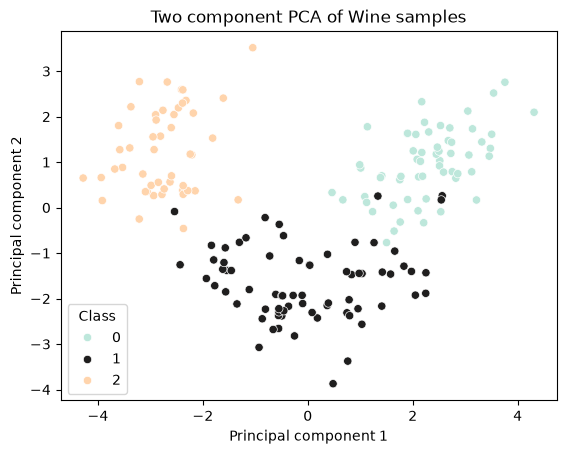

array([[ 3.31675081,  1.44346263],
       [ 2.20946492, -0.33339289],
       [ 2.51674015,  1.0311513 ],
       [ 3.75706561,  2.75637191],
       [ 1.00890849,  0.86983082],
       [ 3.05025392,  2.12240111],
       [ 2.44908967,  1.17485013],
       [ 2.05943687,  1.60896307],
       [ 2.5108743 ,  0.91807096],
       [ 2.75362819,  0.78943767],
       [ 3.47973668,  1.30233324],
       [ 1.7547529 ,  0.61197723],
       [ 2.11346234,  0.67570634],
       [ 3.45815682,  1.13062988],
       [ 4.31278391,  2.09597558],
       [ 2.3051882 ,  1.66255173],
       [ 2.17195527,  2.32730534],
       [ 1.89897118,  1.63136888],
       [ 3.54198508,  2.51834367],
       [ 2.0845222 ,  1.06113799],
       [ 3.12440254,  0.78689711],
       [ 1.08657007,  0.24174355],
       [ 2.53522408, -0.09184062],
       [ 1.64498834, -0.51627893],
       [ 1.76157587, -0.31714893],
       [ 0.9900791 ,  0.94066734],
       [ 1.77527763,  0.68617513],
       [ 1.23542396, -0.08980704],
       [ 2.18840633,

In [5]:
#PCA

def do_pca(data, components:int = 2, is_plot:bool = False, target = None, exp_variance:bool = False):
    pca_model = PCA(n_components=components, random_state= 100)
    pca_data= pca_model.fit(data)
    reduced_data= pca_data.transform(data)
    if is_plot:
        sns.scatterplot(x = reduced_data[:,0], y = reduced_data[:,1], hue = target, palette="icefire")
        plt.xlabel("Principal component 1")
        plt.ylabel("Principal component 2")
        plt.title("Two component PCA of Wine samples")
        plt.legend(title = "Class")
        plt.show()

    if exp_variance:
        return pca_data.explained_variance_ratio_
    return reduced_data
do_pca(wine.data, components= 2, is_plot= True, target = wine.target)

We made a function which performs PCA using sklearn's PCA method. We first fit the model with the wine data, and then transform it seperately. This is so we can get the attributes of both the PCA model, and also ge the dimension reduced data. Inside the function, we make the scatterplot of the individual samples which uses the first two principal components as the two axes, and colours them by the actual classes.


1. Yes, we can easily distinguish them, because there is clear separation between all three classes with very little overlapping, only a small amount between classes 0 and 1, and an even smaller amount between classes 1 and 2.
2. Class 2 is more easily separated from the others, while class 1 and class 0 have slightly more overlap.
3. Each point represents a projection from the transformed dataset $\bar{X}$ onto the two principal component’s eigenvectors.
4. Because we are only using two principal components, any fraction of the variance explained by only other components is lost. Essentially, it is only the variance in two dimensions.

## 4. Explained variance

The variance explained by the first two principal components are: [0.36198848 0.1920749 ]
Variance until explained up to and including 0th component: 0.36198848099926334
Variance until explained up to and including 1th component: 0.5540633835693527
Variance until explained up to and including 2th component: 0.6652996889318525
Variance until explained up to and including 3th component: 0.7359899907589929
Variance until explained up to and including 4th component: 0.8016229275554788
Variance until explained up to and including 5th component: 0.8509811607477045
Variance until explained up to and including 6th component: 0.8933679539739376
Variance until explained up to and including 7th component: 0.9201754434577263
Variance until explained up to and including 8th component: 0.9423969775056235
Variance until explained up to and including 9th component: 0.9616971684450643
Variance until explained up to and including 10th component: 0.9790655253449634
Variance until explained up to and incl

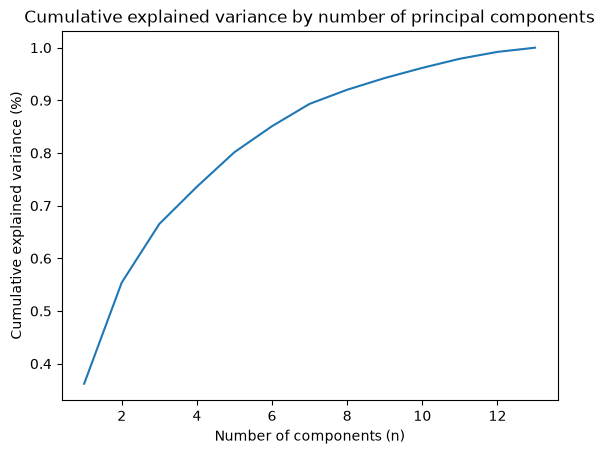

[np.float64(0.36198848099926334),
 np.float64(0.5540633835693527),
 np.float64(0.6652996889318525),
 np.float64(0.7359899907589929),
 np.float64(0.8016229275554788),
 np.float64(0.8509811607477045),
 np.float64(0.8933679539739376),
 np.float64(0.9201754434577263),
 np.float64(0.9423969775056235),
 np.float64(0.9616971684450643),
 np.float64(0.9790655253449634),
 np.float64(0.9920478511010055),
 np.float64(1.0)]

In [6]:
print(f"The variance explained by the first two principal components are: {do_pca(wine.data, components= 2, exp_variance= True)}")
def explained_variance_sum(list_var, is_verbose:bool = False, is_plot:bool = False) -> list[float]:
    cumulative_sums = []
    sum = 0
    for i in range(len(list_var)):
        sum += list_var[i]
        cumulative_sums.append(sum)
        if is_verbose:
            print(f"Variance until explained up to and including {i}th component: {sum}")

    if is_plot:
        sns.lineplot(x = [i for i in range(1, 14)], y = cumulative_sums)
        plt.xlabel("Number of components (n)")
        plt.ylabel("Cumulative explained variance (%)")
        plt.title("Cumulative explained variance by number of principal components")
        plt.show()
    return cumulative_sums

explained_variance_sum(do_pca(wine.data, components= 13, exp_variance= True), is_verbose= True, is_plot= True)

1. The amount of variance explained by the first component is 36.2%, and the by the second 19.2%, which in total is 55.4%.
2. We made a function which takes in a list of explained variances (which the fitted PCA model already provides with the $explained\_variance\_ratio\_$ attribute), and stores and optionally prints the cumulative sums of the explained variances. Thus, we can see that we reach 80% explained variance with 4 components, 80.2% to be exact.
3. With the same function, wen can see that we reach 90% with 7 components, although 6 is almost there as well.
4. The main reasons for using dimensionality reduction despite the loss in explained variance include data visualization, as 2-3 dimensions are required to do so, data preprocessing, where we reduce the dimensionality to a manageable number, and the computational tractability. Not only does it decrease model complexity, it can actually increase generalization, due to only including the most relevant information from the data.

# Part II - Clustering

## 1. Apply K-Means

1. Since K-Means is an unsupervised learning algorithm it operates without beaing able to look at the actual wine labels. K-Means randomly initializes cluster centroids, and iteratively improves them by assigning the data points to the closest centroids and taking the average of those points to create the new centroids. At no point in this algorithm are true labels considered.

2. Classes are the true classifications of the samples, which is typically used in supervised learning. Clusters are similar data points that are grouped together by the machine learning algorithm, typically unsupervised, where we do not have access to actual classes.

## 2. Visualize the clusters using PCA

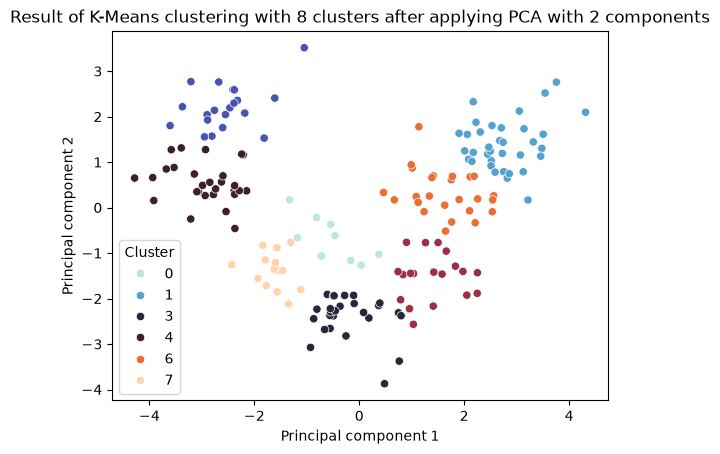

(91.68332329896344, 0.42435978964640714)

In [ ]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples

def do_kmeans(data, n_clusters:int = 8, is_plot:bool = False, is_cluster_silhouette:bool = False):
    kmeans = KMeans(n_clusters=n_clusters, random_state= 100).fit(data)
    wss = kmeans.inertia_
    clustered_data = kmeans.predict(data)
    if is_plot:
        if len(data[0]) != 2:
            raise Exception("Number of components has to be 2 to make a plot")
        sns.scatterplot(x = data[:,0], y = data[:,1], hue = clustered_data, palette="icefire")
        plt.xlabel("Principal component 1")
        plt.ylabel("Principal component 2")
        plt.title(f"Result of K-Means clustering with {n_clusters} clusters after applying PCA with 2 components")
        plt.legend(title = "Cluster")
        plt.show()
        
    if is_cluster_silhouette:
        sample_silhouette_values = silhouette_samples(data, clustered_data)
        cluster_silhouette_values = []
        for i in range(n_clusters):
            ith_cluster_silhouette_values = sample_silhouette_values[clustered_data == i]
            cluster_silhouette_values.append(np.mean(ith_cluster_silhouette_values))
        return wss, silhouette_score(data, clustered_data), sorted(cluster_silhouette_values)
    return wss, silhouette_score(data, clustered_data)

do_kmeans(do_pca(wine.data, 2), n_clusters= 3, is_plot= True)

1. In our plot we can see three clusters, since we selected $k=3$ for K-Means, and in the plot, we coloured the points by the appropiate clusters created by the algorithm.
2. No, the clusters look quite spread.
3. Yes, the clusters are very similar to the actual plot of the wine classes. The only difference is that the clustering cannot account for the datapoints which were overlapping in the classes, instead assigning them to the cluster that they are closest to.


## 3. Experiment with a different number of clusters

In [45]:
def compare_kmeans(min_n_clusters,max_n_clusters, is_elbow_plot:bool = False, is_combined_plot:bool = False, is_verbose:bool = False):
    wss_scores = []
    sihlouette_scores = []
    for i in range(min_n_clusters, max_n_clusters + 1):
        curr_score = do_kmeans(do_pca(wine.data, 2), n_clusters= i)
        wss_scores.append(curr_score[0])
        sihlouette_scores.append(curr_score[1])
        if is_verbose:
            print(curr_score)
    if is_elbow_plot:
        sns.lineplot(x = [i for i in range(min_n_clusters, max_n_clusters + 1)], y = wss_scores)
        plt.xlabel("Number of clusters (k)")
        plt.ylabel("Within Cluster Sum of Squared Errors")
        plt.title("Elbow plot for K-Means WSS")
        plt.show()
    if is_combined_plot:
        fig, ax1 = plt.subplots()
        ax2 = ax1.twinx()
        sns.lineplot(x = [i for i in range(min_n_clusters, max_n_clusters + 1)], y = wss_scores, ax= ax1, color = "blue", label = "WSS")
        sns.lineplot(x = [i for i in range(min_n_clusters, max_n_clusters + 1)], y = sihlouette_scores, ax= ax2, color = "green", label = "Silhouette coefficient")
        ax2.set_ylim(-1,1)
        ax1.set_xlabel("Number of clusters (k)")
        ax1.set_ylabel("Within Cluster Sum of Squared Errors")
        ax2.set_ylabel("Silhouette coefficient")
        plt.legend()
        ax1.legend(loc='upper left')
        plt.title("Elbow plot for K-Means WSS and Silhouette coefficients")
        plt.show()

    return wss_scores, sihlouette_scores

compare_kmeans(2, 8)

([628.788350755478,
  259.80772204980303,
  201.78828568582975,
  169.12999742424287,
  123.01349501833568,
  104.7442954271389,
  91.68332329896344],
 [0.46491409089201524,
  0.5615238075263915,
  0.48567294206220224,
  0.4618405906969397,
  0.43090784838719176,
  0.38745533073845784,
  0.42435978964640714])

1. The WSS decreases when k increases, but silhouette score does not increase, peaks at 3 clusters (same as amount of true classes).
2. k = 3 gives the strongest agreement with the known classes because it has the highest silhouette score, and as we have seen previously, compares very similarly with the known classes visually too.
3. We usually do not know the actual classes, so we should not rely on it. Also, clustering is about discovering patterns in the data. There might be important patterns which are different from the true classes, that we might miss if we hyperfixate on it.


## 4. The Elbow Method

(628.788350755478, 0.46491409089201524)
(259.80772204980303, 0.5615238075263915)
(201.78828568582975, 0.48567294206220224)
(169.12999742424287, 0.4618405906969397)
(123.01349501833568, 0.43090784838719176)
(104.7442954271389, 0.38745533073845784)
(91.68332329896344, 0.42435978964640714)


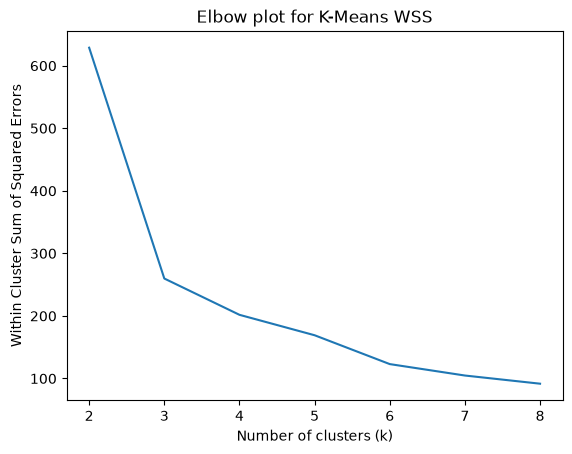

(259.80772204980303, 0.5615238075263915, [np.float64(0.4495129928601497), np.float64(0.6191660970520857), np.float64(0.6452086184700057)])
(201.78828568582975, 0.48567294206220224, [np.float64(0.32121901024039334), np.float64(0.4936567783797639), np.float64(0.5338361526317422), np.float64(0.5950430228881513)])
(169.12999742424287, 0.4618405906969397, [np.float64(0.29102818110325773), np.float64(0.4476906376432918), np.float64(0.4496786130996466), np.float64(0.49023804810409577), np.float64(0.5882350398877808)])
(91.68332329896344, 0.42435978964640714, [np.float64(0.2780026037216741), np.float64(0.34772290590495614), np.float64(0.40729286054399927), np.float64(0.41845817567607063), np.float64(0.4364589309639281), np.float64(0.4520777500631881), np.float64(0.49389749600446436), np.float64(0.52684471933033)])


In [48]:
compare_kmeans(2, 8, is_elbow_plot= True, is_verbose= True)
print(do_kmeans(do_pca(wine.data, components= 2), n_clusters= 3, is_cluster_silhouette= True))
print(do_kmeans(do_pca(wine.data, components= 2), n_clusters= 4, is_cluster_silhouette= True))
print(do_kmeans(do_pca(wine.data, components= 2), n_clusters= 5, is_cluster_silhouette= True))
print(do_kmeans(do_pca(wine.data, components= 2), n_clusters= 8, is_cluster_silhouette= True))


We think that the elbow occurs at 3, since that is the number of classes. After printing it, we weren't sure at which K it occurred, thus, we decided to look at the silhouette scores. With that, we got that the average of the 3 clusters was the best among the other possible k values since it had the highest score. Furthermore, we decided to investigate per custer silhouette scores. In our function which performs K-Means, we added an option to aggregate the silhouette scores per cluster and return it. We can then see that for $k=3$, there is only one cluster below 0.5, while the others sit above 0.6, which is considered a great score. Comperatively, when going to and above $k=4$, most clusters retain a good score, but the added ones have terrible scores. Therefore, even though these extra clusters are driving WSS down, they are actually worse choices than $k=3$.